<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Bike & Sporting Goods Sales Analytics — TrainingSample2<br></h3></center>

# Introduction
This notebook analyses a global bike and sporting goods sales dataset containing ~61,000 transaction records across regions, markets, customers, product categories, models, and pricing tiers. The analysis covers revenue performance, regional distribution, product mix, discount depth, and time-series demand patterns.

## 1. Imports & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (13, 5)

df = pd.read_csv('TrainingSample2_Sales_Data.csv', parse_dates=['SalesDate'])
print(f"Shape: {df.shape}")
df.head()

Shape: (60919, 12)


,Region,SubRegion,Market,Customer,Business Segment,Category,Model,Color,SalesDate,ListPrice,UnitPrice,OrderQty
0,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Silver,2018-11-10,3399.99,2039.99,3
1,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Black,2019-02-25,3374.99,2024.99,2
2,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Black,2019-10-01,3374.99,2024.99,3
3,North America,United States,Southeast,Trusted Catalog Store,Clothing,Socks,Mountain Bike Socks,White,2020-05-21,9.50,5.70,8
4,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Silver,2019-11-29,3399.99,2039.99,1


## 2. Data Overview

In [2]:
print("=== Dtypes ===")
print(df.dtypes)
print()
print("=== Missing Values ===")
print(df.isnull().sum())
print()
print("=== Numeric Summary ===")
df[['ListPrice','UnitPrice','OrderQty']].describe()

=== Dtypes ===
Region                      object
SubRegion                   object
Market                      object
Customer                    object
Business Segment            object
Category                    object
Model                       object
Color                       object
SalesDate           datetime64[ns]
ListPrice                  float64
UnitPrice                  float64
OrderQty                     int64
dtype: object

=== Missing Values ===
Region                 0
SubRegion              0
Market                 0
Customer               0
Business Segment       0
Category               0
Model                  0
Color               5226
SalesDate              0
ListPrice              0
UnitPrice              0
OrderQty               0
dtype: int64

=== Numeric Summary ===


,ListPrice,UnitPrice,OrderQty
count,60919.000000,60919.000000,60919.000000
mean,771.318300,444.277993,3.521332
std,897.975292,519.851905,3.032399
min,2.290000,1.330000,1.000000
25%,59.990000,34.930000,2.000000
50%,364.090000,209.260000,3.000000
75%,1120.490000,672.290000,4.000000
max,3578.270000,2146.960000,44.000000


In [3]:
# Unique counts for categoricals
for col in ['Region','SubRegion','Market','Customer','Business Segment','Category','Model','Color']:
    print(f"{col}: {df[col].nunique()} unique")

Region: 3 unique
SubRegion: 6 unique
Market: 10 unique
Customer: 633 unique
Business Segment: 4 unique
Category: 33 unique
Model: 93 unique
Color: 8 unique


## 3. Feature Engineering

In [4]:
df['Revenue']   = df['UnitPrice'] * df['OrderQty']
df['Discount']  = (df['ListPrice'] - df['UnitPrice']) / df['ListPrice'] * 100
df['Year']      = df['SalesDate'].dt.year
df['Month']     = df['SalesDate'].dt.month
df['Quarter']   = df['SalesDate'].dt.quarter
df['MonthName'] = df['SalesDate'].dt.strftime('%b')

print("Date range:", df['SalesDate'].min().date(), "to", df['SalesDate'].max().date())
print("Total Revenue: ${:,.0f}".format(df['Revenue'].sum()))
df[['Revenue','Discount','Year','Month','Quarter']].head()

Date range: 2018-06-18 to 2024-02-26
Total Revenue: $81,014,827


,Revenue,Discount,Year,Month,Quarter
0,6119.97,40.000118,2018,11,4
1,4049.98,40.000119,2019,2,1
2,6074.97,40.000119,2019,10,4
3,45.60,40.000000,2020,5,2
4,2039.99,40.000118,2019,11,4


## 4. Regional Revenue Performance

In [5]:
region = df.groupby('Region').agg(
    Orders=('Revenue','count'),
    Revenue=('Revenue','sum'),
    Avg_Order=('Revenue','mean'),
    Avg_Discount=('Discount','mean')
).sort_values('Revenue', ascending=False).reset_index()
print(region.to_string(index=False))

       Region  Orders     Revenue   Avg_Order  Avg_Discount
North America   50253 68381907.94 1360.752750     41.821280
       Europe    8953 11010058.46 1229.761919     41.182305
      Pacific    1713  1622860.62  947.379229     41.251859


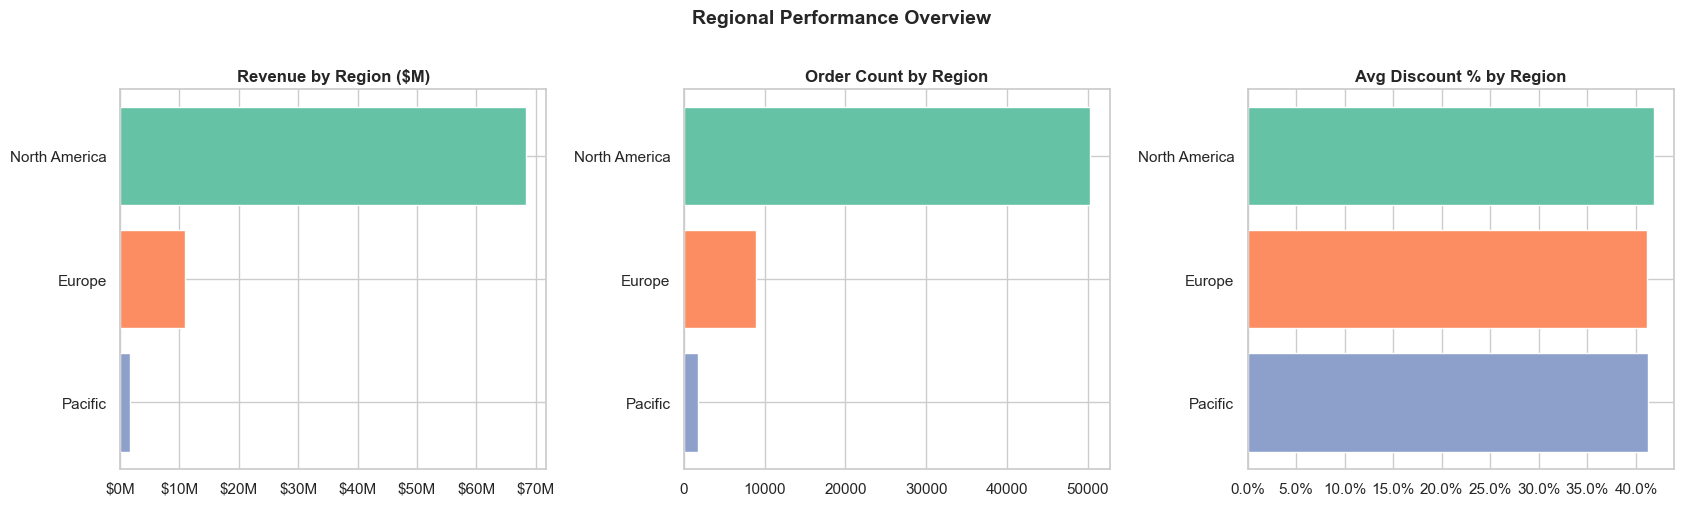

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
colors = sns.color_palette('Set2', len(region))

axes[0].barh(region['Region'], region['Revenue']/1e6, color=colors)
axes[0].invert_yaxis()
axes[0].set_title('Revenue by Region ($M)', fontsize=12, fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].barh(region['Region'], region['Orders'], color=colors)
axes[1].invert_yaxis()
axes[1].set_title('Order Count by Region', fontsize=12, fontweight='bold')

axes[2].barh(region['Region'], region['Avg_Discount'], color=colors)
axes[2].invert_yaxis()
axes[2].set_title('Avg Discount % by Region', fontsize=12, fontweight='bold')
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))

plt.suptitle('Regional Performance Overview', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 5. Sub-Region Analysis

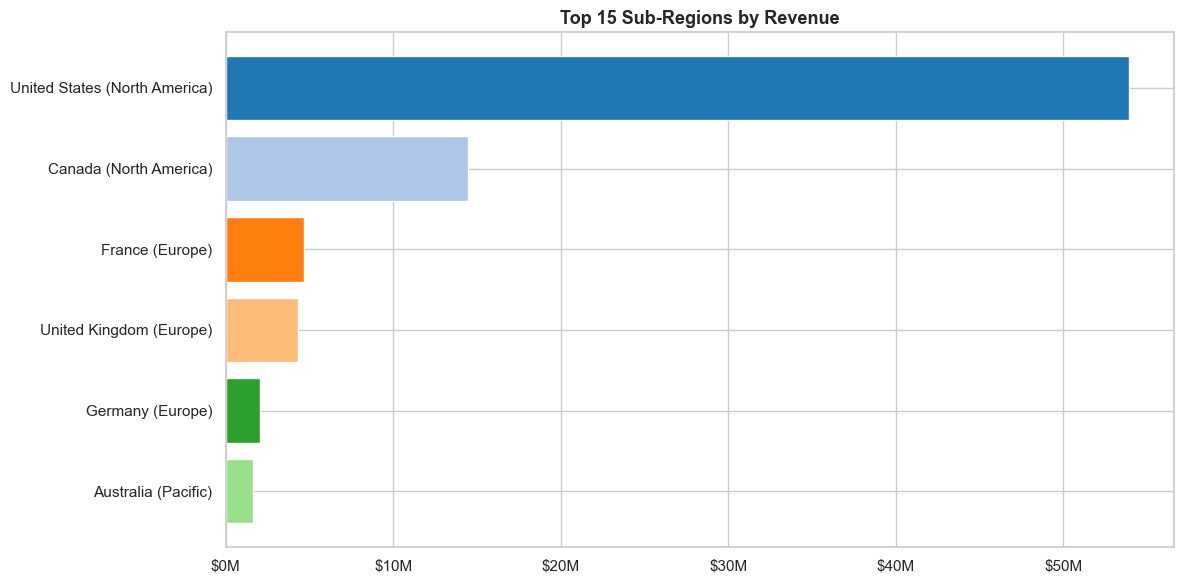

In [7]:
subregion = df.groupby(['Region','SubRegion'])['Revenue'].sum().reset_index().sort_values('Revenue', ascending=False)
top_sr = subregion.head(15)
fig, ax = plt.subplots(figsize=(12, 6))
colors = sns.color_palette('tab20', len(top_sr))
ax.barh(top_sr['SubRegion'] + ' (' + top_sr['Region'] + ')', top_sr['Revenue']/1e6, color=colors)
ax.invert_yaxis()
ax.set_title('Top 15 Sub-Regions by Revenue', fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
plt.tight_layout()
plt.show()

## 6. Market Performance

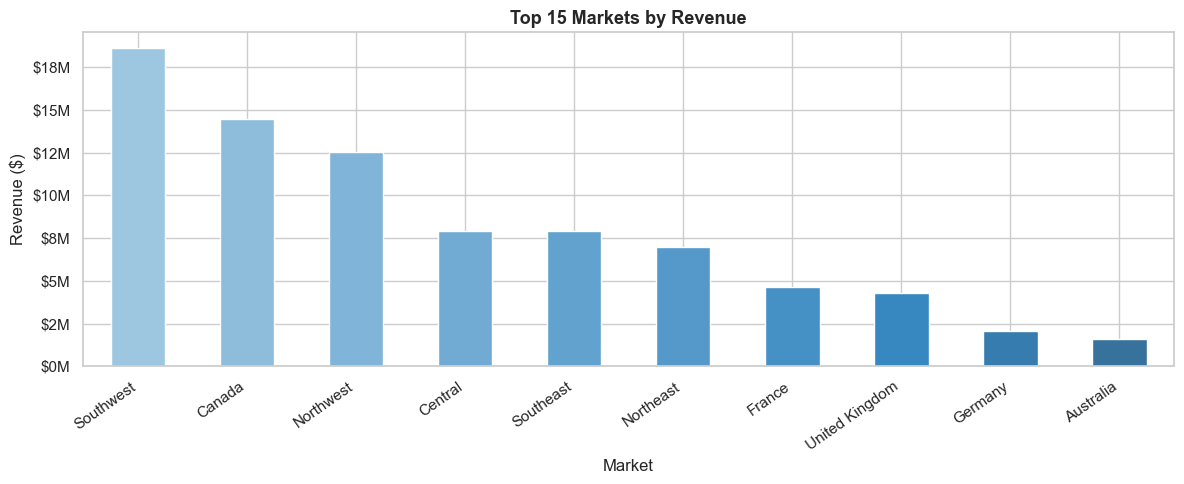

In [8]:
market = df.groupby('Market')['Revenue'].sum().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(12, 5))
market.plot(kind='bar', ax=ax, color=sns.color_palette('Blues_d', 15))
ax.set_title('Top 15 Markets by Revenue', fontsize=13, fontweight='bold')
ax.set_ylabel('Revenue ($)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 7. Customer Revenue Analysis

In [9]:
customer = df.groupby('Customer').agg(
    Revenue=('Revenue','sum'),
    Orders=('Revenue','count'),
    Avg_Order=('Revenue','mean')
).sort_values('Revenue', ascending=False).head(15)
print(customer.to_string())

                                      Revenue  Orders    Avg_Order
Customer                                                          
Brakes and Gears                    882273.53     298  2960.649430
Vigorous Exercise Company           860142.25     530  1622.909906
Excellent Riding Supplies           853848.29     366  2332.918825
Totes & Baskets Company             817125.03     436  1874.139977
Retail Mall                         803767.27     451  1782.189069
Corner Bicycle Supply               787806.32     429  1836.378368
Outdoor Equipment Store             751629.56     332  2263.944458
Thorough Parts and Repair Services  741360.41     358  2070.839134
Health Spa, Limited                 735233.10     352  2088.730398
Fitness Toy Store                   731634.54     336  2177.483750
Latest Sports Equipment             725937.34     332  2186.558253
First Bike Store                    712293.63     312  2282.992404
Great Bikes                         704315.32     290  2428.67

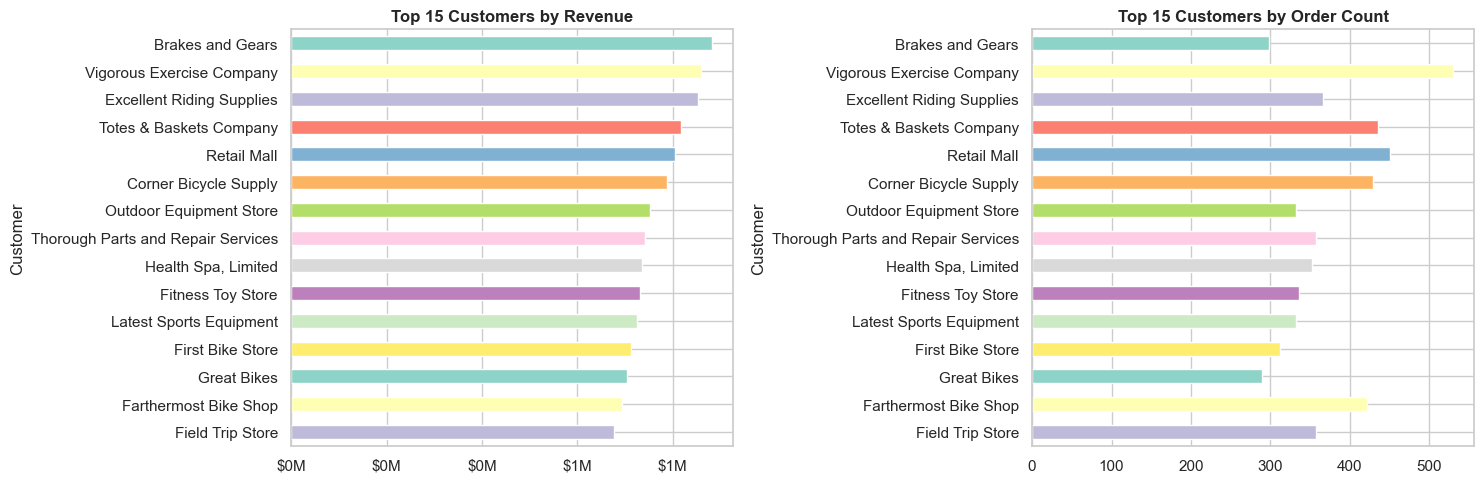

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = sns.color_palette('Set3', 15)

customer['Revenue'].plot(kind='barh', ax=axes[0], color=colors)
axes[0].invert_yaxis()
axes[0].set_title('Top 15 Customers by Revenue', fontsize=12, fontweight='bold')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.0f}M'))

customer['Orders'].plot(kind='barh', ax=axes[1], color=colors)
axes[1].invert_yaxis()
axes[1].set_title('Top 15 Customers by Order Count', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Business Segment Analysis

In [11]:
segment = df.groupby('Business Segment').agg(
    Revenue=('Revenue','sum'),
    Orders=('Revenue','count'),
    Avg_Discount=('Discount','mean')
).sort_values('Revenue', ascending=False).reset_index()
print(segment.to_string(index=False))

Business Segment     Revenue  Orders  Avg_Discount
           Bikes 66827511.81   24826     42.522229
      Components 11807764.77   18698     41.257594
        Clothing  1801581.16   12293     40.890134
     Accessories   577969.28    5102     41.407410


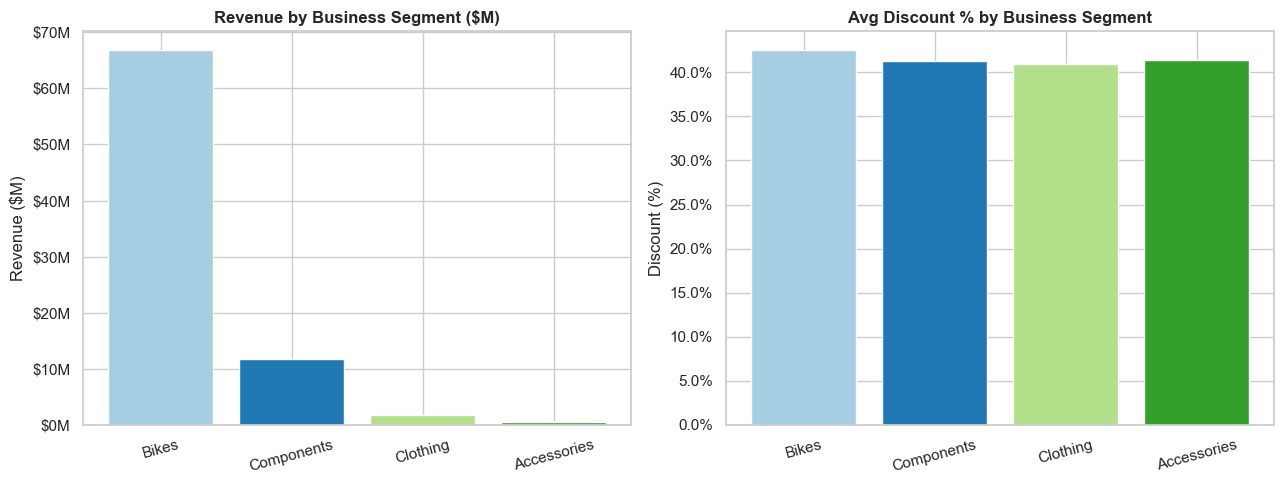

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = sns.color_palette('Paired', len(segment))

axes[0].bar(segment['Business Segment'], segment['Revenue']/1e6, color=colors)
axes[0].set_title('Revenue by Business Segment ($M)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(segment['Business Segment'], segment['Avg_Discount'], color=colors)
axes[1].set_title('Avg Discount % by Business Segment', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Discount (%)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}%'))
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 9. Product Category & Model Performance

In [13]:
cat = df.groupby('Category').agg(
    Revenue=('Revenue','sum'),
    Orders=('Revenue','count'),
    Avg_Price=('UnitPrice','mean')
).sort_values('Revenue', ascending=False).reset_index()
print(cat.to_string(index=False))

         Category     Revenue  Orders   Avg_Price
       Road Bikes 29457771.63   12876  778.793840
   Mountain Bikes 26669470.38    7487 1085.202535
    Touring Bikes 10700269.80    4463  841.250607
  Mountain Frames  4714719.50    4477  432.328318
      Road Frames  3851976.27    4713  335.011018
   Touring Frames  1644939.71    1428  425.496667
           Wheels   681438.17    1904  127.608440
          Jerseys   583661.21    3859   30.132216
           Shorts   349066.71    1591   39.442552
          Helmets   262323.00    2740   20.174558
            Vests   227863.52     876   37.627055
           Gloves   211911.68    2175   18.012133
           Tights   204357.14     977   44.871791
        Cranksets   204060.33     423  179.760213
       Bike Racks   200077.20     468   71.464103
       Handlebars   170645.15    1531   44.724971
       Bib-Shorts   167990.65     762   53.954567
           Pedals   147515.15    1517   37.350382
            Forks    77966.80     200  117.431650


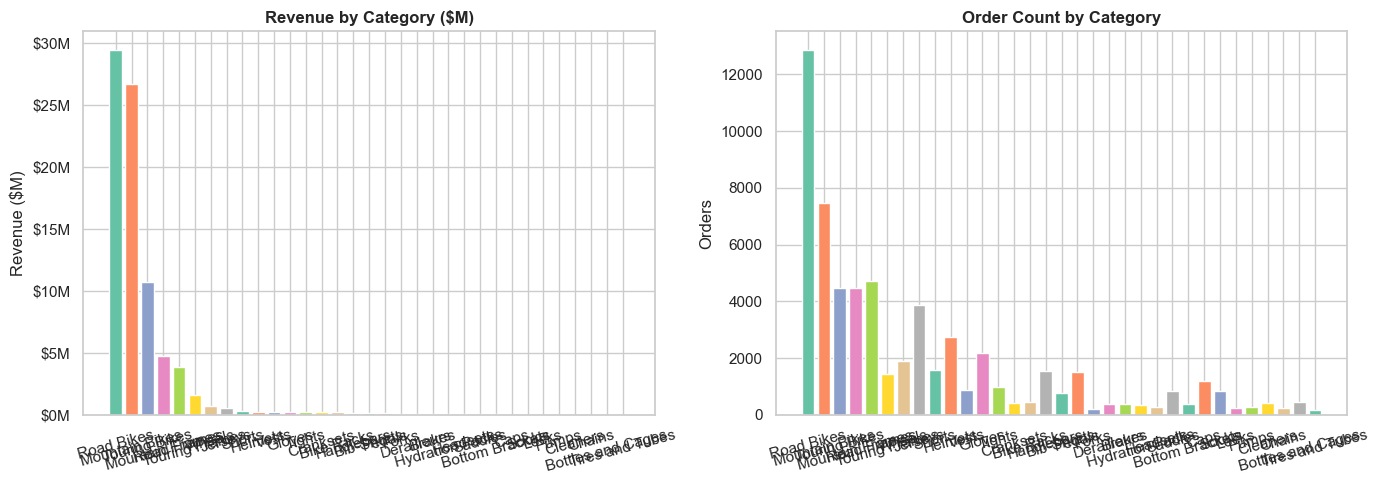

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = sns.color_palette('Set2', len(cat))

axes[0].bar(cat['Category'], cat['Revenue']/1e6, color=colors)
axes[0].set_title('Revenue by Category ($M)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].bar(cat['Category'], cat['Orders'], color=colors)
axes[1].set_title('Order Count by Category', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Orders')

for ax in axes: ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

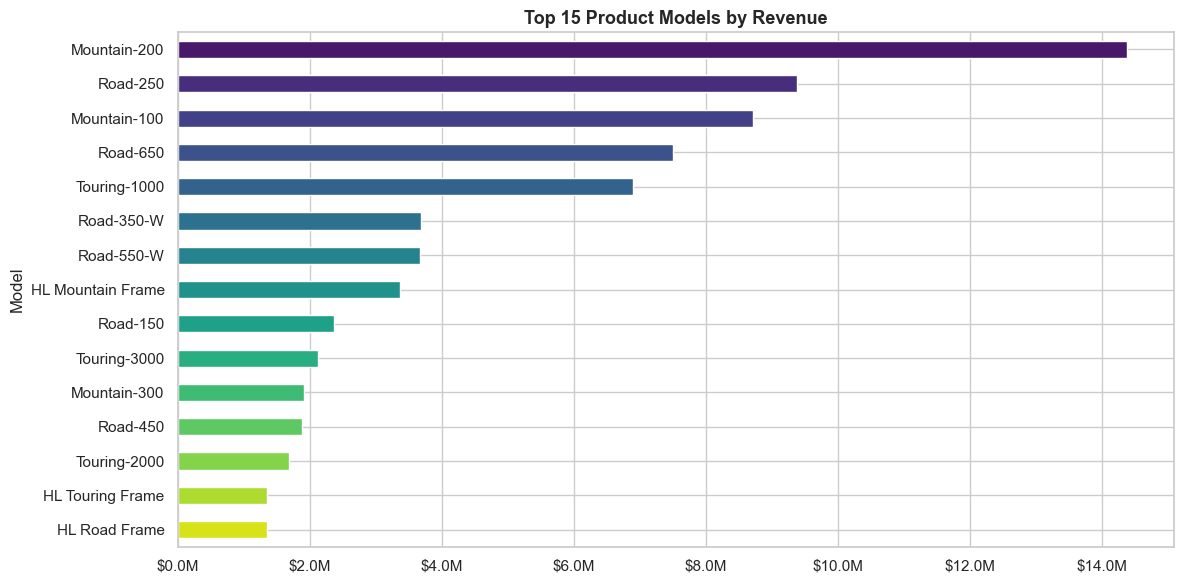

In [15]:
# Top 15 models by revenue
model_rev = df.groupby('Model')['Revenue'].sum().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(12, 6))
model_rev.plot(kind='barh', ax=ax, color=sns.color_palette('viridis', 15))
ax.invert_yaxis()
ax.set_title('Top 15 Product Models by Revenue', fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

## 10. Color Preference Analysis

In [16]:
color_rev = df.groupby('Color').agg(
    Revenue=('Revenue','sum'),
    Orders=('Revenue','count')
).sort_values('Revenue', ascending=False).reset_index()
print(color_rev.to_string(index=False))

       Color     Revenue  Orders
       Black 29521621.96   20256
      Silver 14753210.05    7230
      Yellow 14036890.92    8063
         Red 13935674.25    8116
        Blue  7382071.53    5074
       Multi   545890.17    4576
Silver/Black   147515.15    1517
       White    24910.31     861


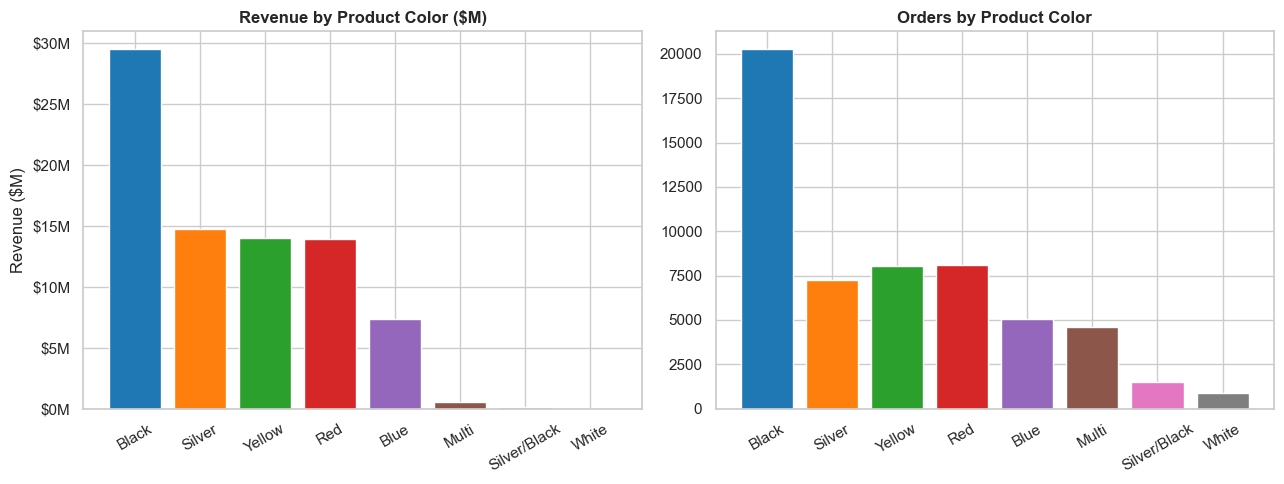

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = sns.color_palette('tab10', len(color_rev))

axes[0].bar(color_rev['Color'], color_rev['Revenue']/1e6, color=palette)
axes[0].set_title('Revenue by Product Color ($M)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(color_rev['Color'], color_rev['Orders'], color=palette)
axes[1].set_title('Orders by Product Color', fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 11. Pricing & Discount Analysis

In [18]:
print("=== Pricing Summary ===")
print(df[['ListPrice','UnitPrice','Discount','Revenue']].describe().round(2))

=== Pricing Summary ===
       ListPrice  UnitPrice  Discount   Revenue
count   60919.00   60919.00  60919.00  60919.00
mean      771.32     444.28     41.71   1329.88
std       897.98     519.85      4.02   2140.47
min         2.29       1.33     26.00      1.37
25%        59.99      34.93     40.00    127.80
50%       364.09     209.26     40.00    461.69
75%      1120.49     672.29     42.30   1472.30
max      3578.27    2146.96     80.00  30993.04


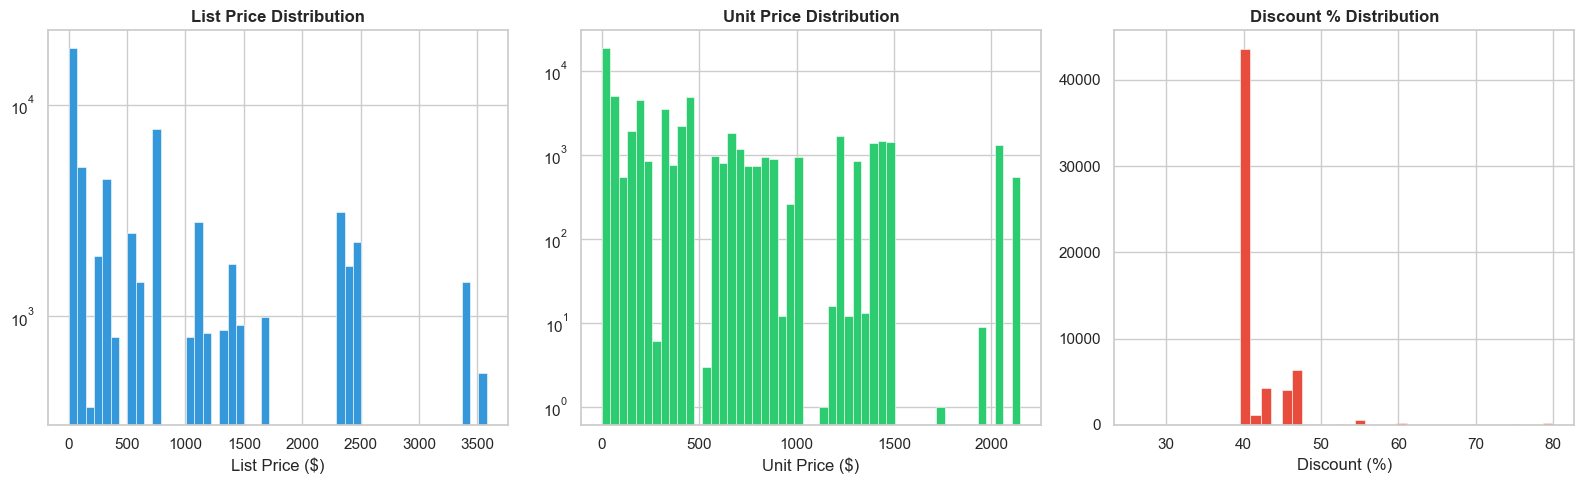

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].hist(df['ListPrice'], bins=50, color='#3498db', edgecolor='white', linewidth=0.4)
axes[0].set_title('List Price Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('List Price ($)')
axes[0].set_yscale('log')

axes[1].hist(df['UnitPrice'], bins=50, color='#2ecc71', edgecolor='white', linewidth=0.4)
axes[1].set_title('Unit Price Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Unit Price ($)')
axes[1].set_yscale('log')

axes[2].hist(df['Discount'], bins=40, color='#e74c3c', edgecolor='white', linewidth=0.4)
axes[2].set_title('Discount % Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Discount (%)')

plt.tight_layout()
plt.show()

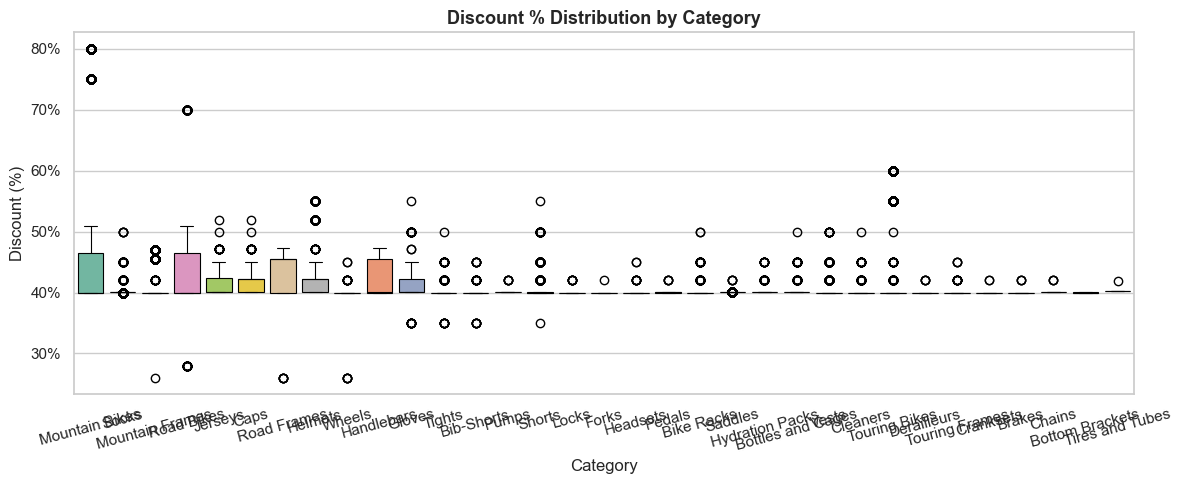

In [20]:
# Discount by Category
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x='Category', y='Discount', ax=ax,
            linecolor='black', linewidth=0.8, palette='Set2')
ax.set_title('Discount % Distribution by Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Discount (%)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 12. Order Quantity Analysis

In [21]:
print(df['OrderQty'].value_counts().sort_index().to_string())
print()
print("Mean OrderQty:", round(df['OrderQty'].mean(), 2))
print("Max  OrderQty:", df['OrderQty'].max())

OrderQty
1     14556
2     14200
3     10058
4      7494
5      4386
6      3298
7      1735
8      1521
9       837
10      768
11      392
12      466
13      230
14      265
15      119
16      133
17       94
18      101
19       53
20       46
21       31
22       12
23       23
24       19
25       17
26       15
27        9
28        6
29        3
30        1
31        5
32        7
33        6
34        3
35        2
36        2
38        1
39        1
40        2
41        1
44        1

Mean OrderQty: 3.52
Max  OrderQty: 44


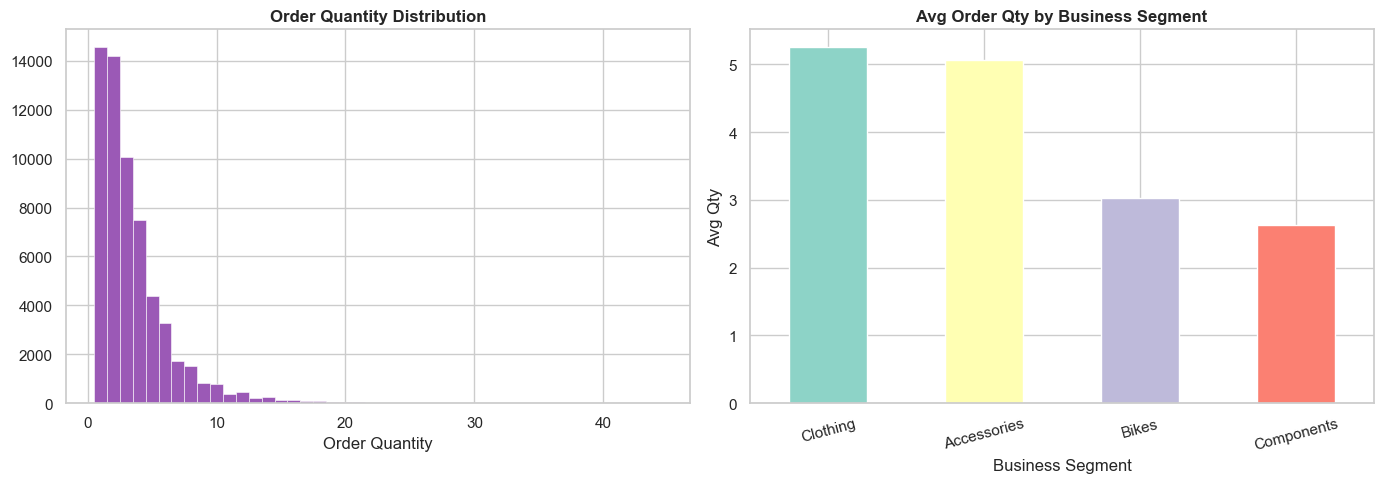

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['OrderQty'], bins=range(1, int(df['OrderQty'].max())+2),
             color='#9b59b6', edgecolor='white', linewidth=0.4, align='left')
axes[0].set_title('Order Quantity Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Order Quantity')

qty_seg = df.groupby('Business Segment')['OrderQty'].mean().sort_values(ascending=False)
qty_seg.plot(kind='bar', ax=axes[1], color=sns.color_palette('Set3', len(qty_seg)))
axes[1].set_title('Avg Order Qty by Business Segment', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Avg Qty')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## 13. Sales Trends Over Time

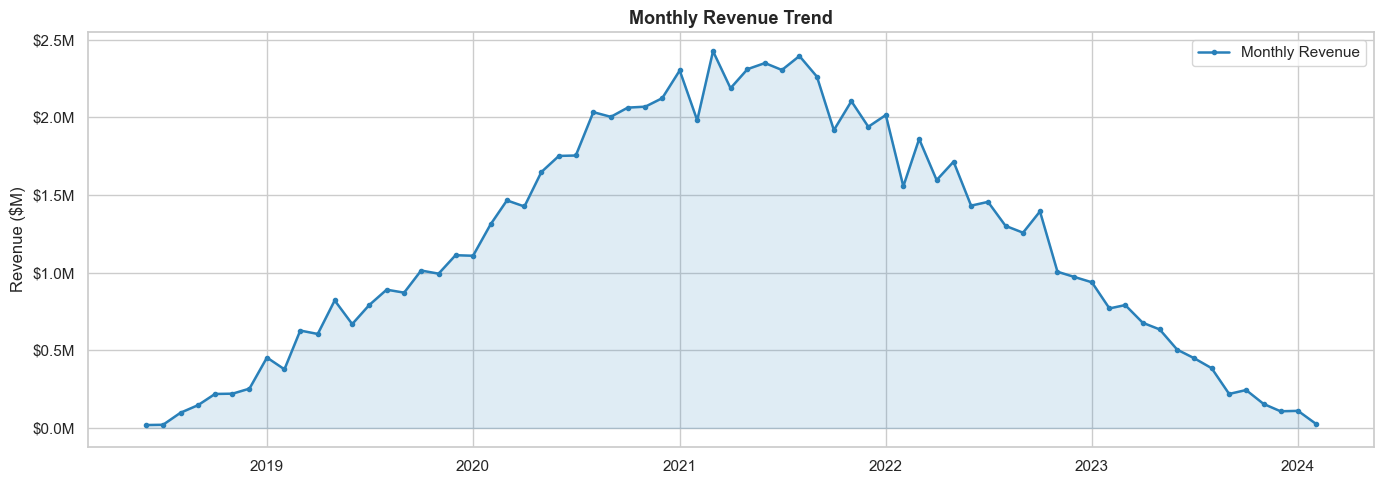

In [23]:
monthly = df.groupby(['Year','Month'])['Revenue'].sum().reset_index()
monthly['Period'] = pd.to_datetime(monthly[['Year','Month']].assign(day=1))
monthly = monthly.sort_values('Period')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly['Period'], monthly['Revenue']/1e6, marker='o', markersize=3,
        color='#2980b9', linewidth=1.8, label='Monthly Revenue')
ax.fill_between(monthly['Period'], monthly['Revenue']/1e6, alpha=0.15, color='#2980b9')
ax.set_title('Monthly Revenue Trend', fontsize=13, fontweight='bold')
ax.set_ylabel('Revenue ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))
ax.legend()
plt.tight_layout()
plt.show()

In [24]:
yearly = df.groupby('Year').agg(
    Revenue=('Revenue','sum'),
    Orders=('Revenue','count'),
    Avg_Order_Value=('Revenue','mean')
).reset_index()
print(yearly.to_string(index=False))

 Year     Revenue  Orders  Avg_Order_Value
 2018   977635.26     527      1855.095370
 2019  9226391.37    6375      1447.277078
 2020 20756277.08   16068      1291.777264
 2021 26479393.74   20325      1302.799200
 2022 17561092.32   13731      1278.937610
 2023  5875308.58    3836      1531.623717
 2024   138728.67      57      2433.836316


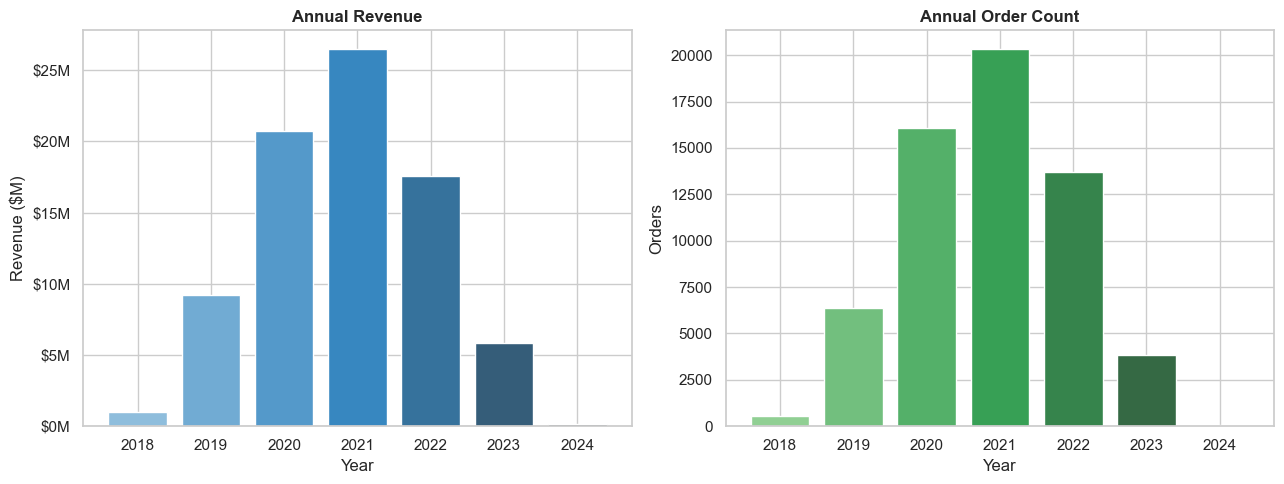

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
years = yearly['Year'].astype(str)

axes[0].bar(years, yearly['Revenue']/1e6, color=sns.color_palette('Blues_d', len(years)))
axes[0].set_title('Annual Revenue', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue ($M)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

axes[1].bar(years, yearly['Orders'], color=sns.color_palette('Greens_d', len(years)))
axes[1].set_title('Annual Order Count', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Orders')

for ax in axes: ax.set_xlabel('Year')
plt.tight_layout()
plt.show()

## 14. Quarterly Seasonality

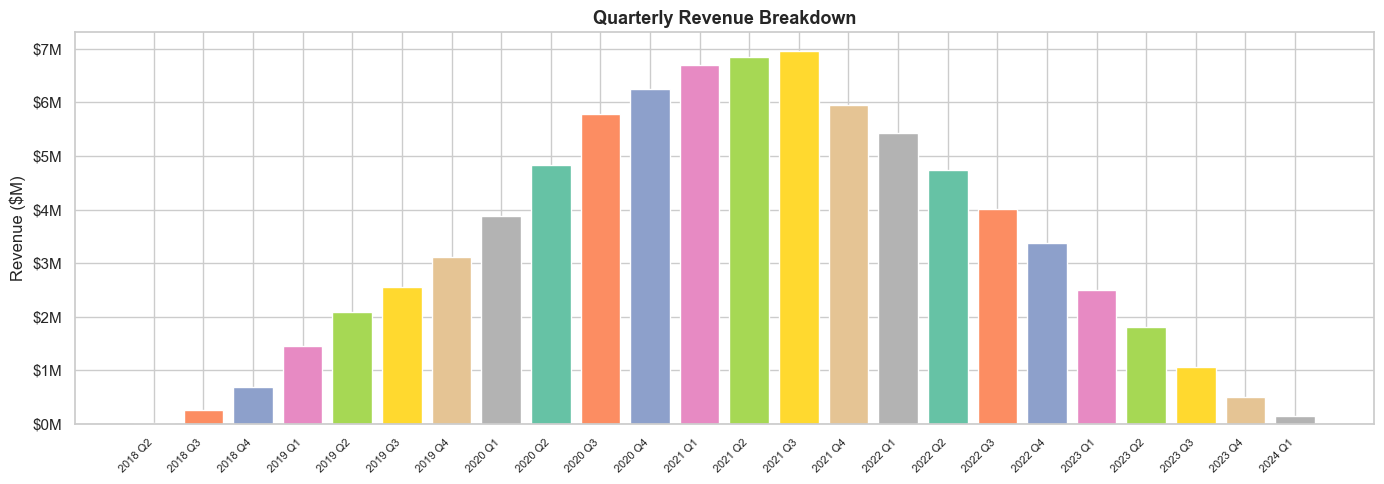

In [26]:
quarterly = df.groupby(['Year','Quarter'])['Revenue'].sum().reset_index()
quarterly['Label'] = quarterly['Year'].astype(str) + ' Q' + quarterly['Quarter'].astype(str)

fig, ax = plt.subplots(figsize=(14, 5))
x = range(len(quarterly))
ax.bar(list(x), quarterly['Revenue']/1e6, color=sns.color_palette('Set2', len(quarterly)))
ax.set_xticks(list(x))
ax.set_xticklabels(quarterly['Label'], rotation=45, ha='right', fontsize=8)
ax.set_title('Quarterly Revenue Breakdown', fontsize=13, fontweight='bold')
ax.set_ylabel('Revenue ($M)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
plt.tight_layout()
plt.show()

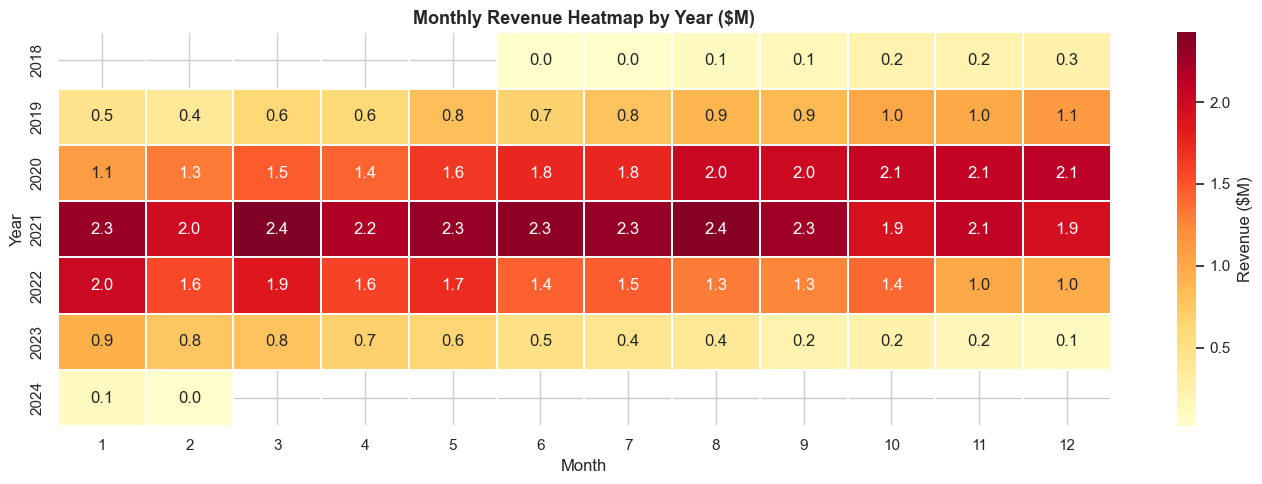

In [27]:
# Heatmap: average monthly revenue by year
pivot = df.pivot_table(values='Revenue', index='Year', columns='Month', aggfunc='sum') / 1e6
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            linewidths=0.3, cbar_kws={'label': 'Revenue ($M)'})
ax.set_title('Monthly Revenue Heatmap by Year ($M)', fontsize=13, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Year')
plt.tight_layout()
plt.show()

## 15. Category Mix by Region

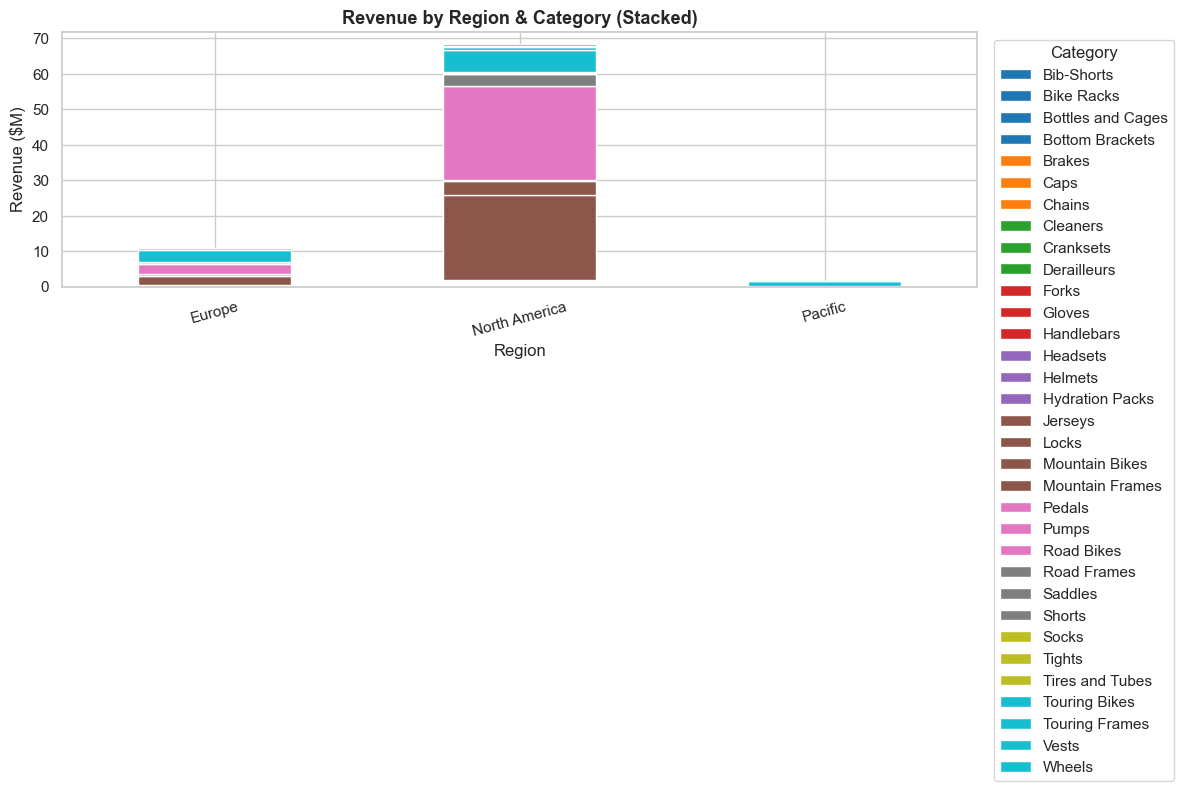

In [28]:
cat_region = df.pivot_table(values='Revenue', index='Region', columns='Category', aggfunc='sum') / 1e6
cat_region.plot(kind='bar', stacked=True, figsize=(12, 6),
                colormap='tab10')
plt.title('Revenue by Region & Category (Stacked)', fontsize=13, fontweight='bold')
plt.ylabel('Revenue ($M)')
plt.xlabel('Region')
plt.legend(title='Category', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 16. Correlation Analysis

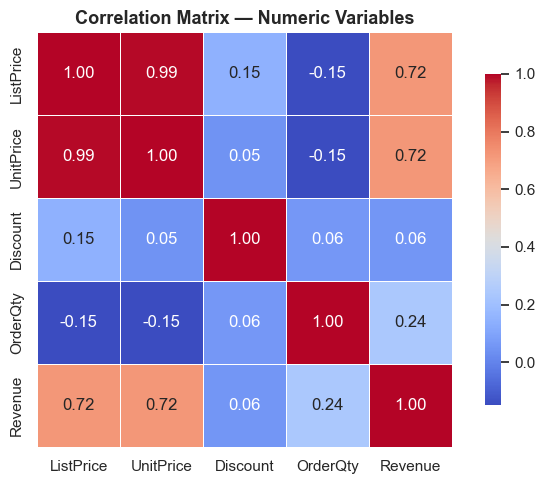

In [29]:
num_cols = ['ListPrice','UnitPrice','Discount','OrderQty','Revenue']
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            linewidths=0.5, square=True, cbar_kws={'shrink':0.8})
ax.set_title('Correlation Matrix — Numeric Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 17. Executive Summary

In [30]:
total_rev     = df['Revenue'].sum()
total_orders  = len(df)
avg_order_val = df['Revenue'].mean()
avg_discount  = df['Discount'].mean()
top_region    = df.groupby('Region')['Revenue'].sum().idxmax()
top_country   = df.groupby('SubRegion')['Revenue'].sum().idxmax()
top_market    = df.groupby('Market')['Revenue'].sum().idxmax()
top_customer  = df.groupby('Customer')['Revenue'].sum().idxmax()
top_segment   = df.groupby('Business Segment')['Revenue'].sum().idxmax()
top_category  = df.groupby('Category')['Revenue'].sum().idxmax()
top_model     = df.groupby('Model')['Revenue'].sum().idxmax()

print("=" * 60)
print("     TRAININGSAMPLE2 — SALES ANALYTICS KEY INSIGHTS")
print("=" * 60)
print(f"  Total Records         : {total_orders:,}")
print(f"  Total Revenue         : ${total_rev:,.0f}")
print(f"  Avg Order Value       : ${avg_order_val:,.2f}")
print(f"  Avg Discount          : {avg_discount:.1f}%")
print(f"  Top Region            : {top_region}")
print(f"  Top Sub-Region        : {top_country}")
print(f"  Top Market            : {top_market}")
print(f"  Top Customer          : {top_customer}")
print(f"  Top Business Segment  : {top_segment}")
print(f"  Top Category          : {top_category}")
print(f"  Top Model             : {top_model}")
print(f"  Date Range            : {df['SalesDate'].min().date()} to {df['SalesDate'].max().date()}")
print(f"  Unique Models         : {df['Model'].nunique()}")
print(f"  Unique Colors         : {df['Color'].nunique()}")
print(f"  Unique Customers      : {df['Customer'].nunique()}")
print("=" * 60)

     TRAININGSAMPLE2 — SALES ANALYTICS KEY INSIGHTS
  Total Records         : 60,919
  Total Revenue         : $81,014,827
  Avg Order Value       : $1,329.88
  Avg Discount          : 41.7%
  Top Region            : North America
  Top Sub-Region        : United States
  Top Market            : Southwest
  Top Customer          : Brakes and Gears
  Top Business Segment  : Bikes
  Top Category          : Road Bikes
  Top Model             : Mountain-200
  Date Range            : 2018-06-18 to 2024-02-26
  Unique Models         : 93
  Unique Colors         : 8
  Unique Customers      : 633
